# Kerala Landslide Dataset

1. Extract the original Kerala data ZIP.
2. Load and validate the **4,728 original landslide points**.
3. Export an untouched master inventory to `kerala_landslide_master.csv`.
4. Prepare a 30 m DEM in UTM Zone 43N (EPSG:32643).
5. Derive elevation, slope, aspect, plan curvature, profile curvature, TWI and SPI.
6. Obtain Kerala boundary and OSM river/road layers.
7. Generate an equal number of pseudo-absence (non-landslide) points outside a configurable exclusion buffer.
8. Calculate distance to rivers and roads.
9. Sample all factors at both landslide and non-landslide points.
10. Add geology and land-use only when valid Kerala-wide layers are supplied.
11. Save a core dataset and, when all 11 factors exist, the exact Indonesia-style 17-column dataset.



## 0. Packages

Run the following installation cell **once** if your environment does not already contain these packages. WhiteboxTools is used for terrain and hydrological derivatives; OSMnx is used for the Kerala boundary and road/river data.


In [1]:

%pip install -U geopandas rasterio pyogrio shapely pyproj pandas numpy osmnx whitebox pyarrow


^C
Note: you may need to restart the kernel to use updated packages.


  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.3 requires numpy<2.0,>=1.18.5, but you have numpy 2.4.6 which is incompatible.
scipy 1.12.0 requires numpy<1.29.0,>=1.22.4, but you have numpy 2.4.6 which is incompatible.
streamlit 1.45.1 requires pandas<3,>=1.4.0, but you have pandas 3.0.5 which is incompatible.
tensorflow-intel 2.18.0 requires numpy<2.1.0,>=1.26.0, but you have numpy 2.4.6 which is incompatible.

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: C:\Users\PCC\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.0 MB ? eta -:--:--
   - -------------------------------------- 0.3/10.0 MB ? eta -:--:--
   - -------------------------------------- 0.3/10.0 MB ? eta -:--:--
   -- ------------------------------------- 0.5/10.0 MB 465.6 kB/s eta 0:00:21
   -- ------------------------------------- 0.5/10.0 MB 465.6 kB/s eta 0:00:21
   -- ------------------------------------- 0.5/10.0 MB 465.6 kB/s eta 0:00:21
   --- ------------------------------------ 0.8/10.0 MB 441.3 kB/s eta 0:00:21
   --- ------------------------------------ 0.8/10.0 MB 441.3 kB/s eta 0:00:21
   --- ------------------------------------ 0.8/10.0 MB 441.3 kB/s eta 0:00:21
   ---- ----------------------------------- 1.0/10.0 MB 453.3 kB/s eta 0:00:20
   ---- -------------------

In [1]:
# 1 — Imports
from pathlib import Path
from datetime import datetime, timezone
import json
import math
import time
import warnings
import zipfile

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask as rio_mask
from rasterio.warp import calculate_default_transform, reproject, Resampling
from shapely.geometry import Point, box
from shapely.prepared import prep

warnings.filterwarnings('ignore', category=UserWarning)

print('GeoPandas:', gpd.__version__)
print('Rasterio:', rasterio.__version__)


GeoPandas: 1.1.4
Rasterio: 1.4.4


In [2]:
# 2 — Configuration

from pathlib import Path

# Notebook is inside /notebooks, so project root is one level above
PROJECT_ROOT = Path.cwd().resolve().parent

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw" / "Kerala_dataset"
PROCESSED_DIR = DATA_DIR / "processed"
FACTOR_DIR = PROCESSED_DIR / "kerala_factors"

# OSM tiles folder
OSM_DIR = RAW_DIR / "osm_tiles"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FACTOR_DIR.mkdir(parents=True, exist_ok=True)
OSM_DIR.mkdir(parents=True, exist_ok=True)

TARGET_CRS = "EPSG:32643"
TARGET_RESOLUTION_M = 30
RANDOM_STATE = 42
EXCLUSION_BUFFER_M = 1000
N_GRID = 6

GEOLOGY_PATH = None
LANDUSE_PATH = None

print("Project root:", PROJECT_ROOT)
print("Kerala folder:", RAW_DIR)
print("Kerala folder exists:", RAW_DIR.exists())
print("OSM folder:", OSM_DIR)

Project root: D:\PROJECTS\Landslide_prediction
Kerala folder: D:\PROJECTS\Landslide_prediction\data\raw\Kerala_dataset
Kerala folder exists: True
OSM folder: D:\PROJECTS\Landslide_prediction\data\raw\Kerala_dataset\osm_tiles


## 1. Extract and validate the original Kerala inventory

The source ZIP is extracted only into `data/raw/kerala/source`. The original source files are not modified.


In [3]:
# 3 — File paths

INVENTORY_PATH = RAW_DIR / "Kerela landslide.shp"

# Change this filename only if your DEM has a different name
DEM_RAW_PATH = RAW_DIR / "kerala_dem_raw.tif"

print("Inventory:", INVENTORY_PATH)
print("DEM:", DEM_RAW_PATH)

print("Inventory exists:", INVENTORY_PATH.exists())
print("DEM exists:", DEM_RAW_PATH.exists())

Inventory: D:\PROJECTS\Landslide_prediction\data\raw\Kerala_dataset\Kerela landslide.shp
DEM: D:\PROJECTS\Landslide_prediction\data\raw\Kerala_dataset\kerala_dem_raw.tif
Inventory exists: True
DEM exists: True


In [4]:
print(OSM_DIR)
print(OSM_DIR.exists())

D:\PROJECTS\Landslide_prediction\data\raw\Kerala_dataset\osm_tiles
True


In [5]:
# 4 — Load Kerala landslide data

kerala_raw = gpd.read_file(INVENTORY_PATH)

print("Shape:", kerala_raw.shape)
print("CRS:", kerala_raw.crs)

print("\nColumns:")
print(kerala_raw.columns.tolist())

print("\nGeometry types:")
print(kerala_raw.geom_type.value_counts())

# Check number of records
print("\nNumber of landslides:", len(kerala_raw))

# Check missing geometry
print("Missing geometries:", kerala_raw.geometry.isna().sum())

# Check duplicates
print("Duplicate locations:", kerala_raw.geometry.duplicated().sum())

# Convert to latitude/longitude
kerala_wgs84 = kerala_raw.to_crs("EPSG:4326")

print("\nWGS84 bounds:")
print(kerala_wgs84.total_bounds)

kerala_wgs84.head()

Shape: (4728, 21)
CRS: EPSG:4326

Columns:
['No', 'District', 'NRSC', 'GSI', 'New', 'Type_of_sl', 'Length', 'Width', 'Area', 'Building_I', 'Road_impac', 'Impact_Agr', 'LU_2010', 'LU_2018', 'Specific_r', 'Remarks', 'POINT_X', 'POINT_Y', 'Reclass_Sl', 'RASTERVALU', 'geometry']

Geometry types:
Point    4728
Name: count, dtype: int64

Number of landslides: 4728
Missing geometries: 0
Duplicate locations: 0

WGS84 bounds:
[75.015414    8.474453   77.39626239 12.654953  ]


,No,District,NRSC,GSI,New,Type_of_sl,Length,Width,Area,Building_I,...,Impact_Agr,LU_2010,LU_2018,Specific_r,Remarks,POINT_X,POINT_Y,Reclass_Sl,RASTERVALU,geometry
0,1,Ernakulam,Y,Y,N,DF,98,26,2548.000,0,...,FMP,FMP,FMP,NaN,Two quarters belonging to Kerala Plantation Co...,76.484939,10.286001,5,26.049702,POINT Z (76.48494 10.286 0)
1,2,Ernakulam,Y,N,N,DF,0,0,647.432,0,...,N,BRF,BRF,NaN,NaN,76.799174,10.074998,8,43.726994,POINT Z (76.79917 10.075 0)
2,3,Ernakulam,Y,N,N,DF,0,0,3000.000,0,...,N,BRF,BRF,NaN,NaN,76.845895,10.093431,7,35.940510,POINT Z (76.8459 10.09343 0)
3,4,Ernakulam,Y,N,N,DF,0,0,2962.660,0,...,N,BRF,BRF,NaN,NaN,76.848402,10.270994,5,28.758051,POINT Z (76.8484 10.27099 0)
4,5,Ernakulam,Y,N,N,DF,0,0,5123.880,0,...,N,BRF,BRF,NaN,NaN,76.895042,10.252606,8,41.060772,POINT Z (76.89504 10.25261 0)


## 2. Export the 4,728-point master CSV

CSV cannot store a native GIS geometry object, so the geometry is serialized as WKT text. All original attribute fields are retained. The source shapefile remains the authoritative spatial master.


In [6]:
# 5 — Save master inventory CSV BEFORE creating any training labels or pseudo-absence points
MASTER_CSV = PROCESSED_DIR / 'kerala_landslide_master.csv'
MASTER_GPKG = PROCESSED_DIR / 'kerala_landslide_master.gpkg'

master_csv = kerala_raw.copy()
master_csv['geometry'] = master_csv.geometry.to_wkt()
master_csv.to_csv(MASTER_CSV, index=False, encoding='utf-8-sig')

# GeoPackage preserves the native geometry and CRS as an additional archival copy.
if not MASTER_GPKG.exists():
    kerala_raw.to_file(MASTER_GPKG, layer='landslides', driver='GPKG')

print('Saved CSV :', MASTER_CSV)
print('Saved GPKG:', MASTER_GPKG)
print('Rows:', len(master_csv))
master_csv.head()


Saved CSV : D:\PROJECTS\Landslide_prediction\data\processed\kerala_landslide_master.csv
Saved GPKG: D:\PROJECTS\Landslide_prediction\data\processed\kerala_landslide_master.gpkg
Rows: 4728


,No,District,NRSC,GSI,New,Type_of_sl,Length,Width,Area,Building_I,...,Impact_Agr,LU_2010,LU_2018,Specific_r,Remarks,POINT_X,POINT_Y,Reclass_Sl,RASTERVALU,geometry
0,1,Ernakulam,Y,Y,N,DF,98,26,2548.000,0,...,FMP,FMP,FMP,NaN,Two quarters belonging to Kerala Plantation Co...,76.484939,10.286001,5,26.049702,POINT Z (76.484939 10.286001 0)
1,2,Ernakulam,Y,N,N,DF,0,0,647.432,0,...,N,BRF,BRF,NaN,NaN,76.799174,10.074998,8,43.726994,POINT Z (76.799174 10.074998 0)
2,3,Ernakulam,Y,N,N,DF,0,0,3000.000,0,...,N,BRF,BRF,NaN,NaN,76.845895,10.093431,7,35.940510,POINT Z (76.845895 10.093431 0)
3,4,Ernakulam,Y,N,N,DF,0,0,2962.660,0,...,N,BRF,BRF,NaN,NaN,76.848402,10.270994,5,28.758051,POINT Z (76.848402 10.270994 0)
4,5,Ernakulam,Y,N,N,DF,0,0,5123.880,0,...,N,BRF,BRF,NaN,NaN,76.895042,10.252606,8,41.060772,POINT Z (76.895042 10.252606 0)


## 3. Obtain a Kerala state boundary

For pseudo-absence generation, use the actual state boundary rather than the landslide-point bounding box. The boundary is fetched once from OpenStreetMap/Nominatim and cached locally. If your research requires a specific authoritative administrative boundary, replace the cached file with that boundary before continuing.


In [7]:
# 6 — Kerala boundary (cached)
BOUNDARY_PATH = RAW_DIR / 'kerala_boundary.gpkg'

if BOUNDARY_PATH.exists():
    kerala_boundary = gpd.read_file(BOUNDARY_PATH)
    print('Loaded cached Kerala boundary.')
else:
    import osmnx as ox
    kerala_boundary = ox.geocode_to_gdf('Kerala, India')[['geometry']].copy()
    kerala_boundary = kerala_boundary.to_crs('EPSG:4326')
    kerala_boundary.to_file(BOUNDARY_PATH, layer='kerala', driver='GPKG')
    print('Downloaded and cached Kerala boundary.')

kerala_boundary = kerala_boundary.to_crs('EPSG:4326')
state_geom_wgs84 = kerala_boundary.geometry.union_all()
assert not state_geom_wgs84.is_empty

print('Boundary CRS:', kerala_boundary.crs)
print('Boundary bounds:', kerala_boundary.total_bounds)


Loaded cached Kerala boundary.
Boundary CRS: EPSG:4326
Boundary bounds: [74.8640682  8.2935318 77.4123612 12.7960559]


## 4. Prepare the 30 m DEM in EPSG:32643

The uploaded DEM is first clipped to the Kerala boundary, then reprojected to UTM Zone 43N at 30 m. The resulting raster becomes the reference grid for terrain factors.


In [8]:
# 7 — Clip source DEM to Kerala boundary
DEM_CLIPPED_WGS84 = PROCESSED_DIR / 'kerala_dem_clipped_wgs84.tif'

if not DEM_CLIPPED_WGS84.exists():
    with rasterio.open(DEM_RAW_PATH) as src:
        boundary_in_dem_crs = kerala_boundary.to_crs(src.crs)
        shapes = [g.__geo_interface__ for g in boundary_in_dem_crs.geometry]
        out_img, out_transform = rio_mask(src, shapes, crop=True, nodata=src.nodata)
        meta = src.meta.copy()
        meta.update(
            driver='GTiff',
            height=out_img.shape[1],
            width=out_img.shape[2],
            transform=out_transform,
            compress='deflate'
        )
        with rasterio.open(DEM_CLIPPED_WGS84, 'w', **meta) as dst:
            dst.write(out_img)
    print('Created:', DEM_CLIPPED_WGS84)
else:
    print('Reusing:', DEM_CLIPPED_WGS84)


Reusing: D:\PROJECTS\Landslide_prediction\data\processed\kerala_dem_clipped_wgs84.tif


In [9]:
# 8 — Reproject clipped DEM to EPSG:32643 at exactly 30 m
DEM_UTM = FACTOR_DIR / 'map_elev.tif'

if not DEM_UTM.exists():
    with rasterio.open(DEM_CLIPPED_WGS84) as src:
        transform, width, height = calculate_default_transform(
            src.crs, TARGET_CRS, src.width, src.height, *src.bounds,
            resolution=TARGET_RESOLUTION_M
        )
        meta = src.meta.copy()
        meta.update(
            crs=TARGET_CRS,
            transform=transform,
            width=width,
            height=height,
            dtype='float32',
            compress='deflate'
        )
        with rasterio.open(DEM_UTM, 'w', **meta) as dst:
            reproject(
                source=rasterio.band(src, 1),
                destination=rasterio.band(dst, 1),
                src_transform=src.transform,
                src_crs=src.crs,
                src_nodata=src.nodata,
                dst_transform=transform,
                dst_crs=TARGET_CRS,
                dst_nodata=src.nodata,
                resampling=Resampling.bilinear
            )
    print('Created:', DEM_UTM)
else:
    print('Reusing:', DEM_UTM)

with rasterio.open(DEM_UTM) as src:
    print('DEM shape:', src.shape)
    print('DEM CRS:', src.crs)
    print('DEM resolution:', src.res)
    print('DEM nodata:', src.nodata)


Reusing: D:\PROJECTS\Landslide_prediction\data\processed\kerala_factors\map_elev.tif
DEM shape: (15817, 8984)
DEM CRS: EPSG:32643
DEM resolution: (30.0, 30.0)
DEM nodata: -32768.0


## 5. Terrain and hydrological conditioning factors

The Indonesia table contains `elev`, `slope`, `aspect`, `planc`, `profc`, `twi`, and `spi`. Here they are derived from the same 30 m reference DEM.

For TWI and SPI, flow accumulation is explicitly generated as **specific contributing area (SCA)** and is not log-transformed before calculating the indices.


In [10]:
# 9 — Generate terrain derivatives using WhiteboxTools
import whitebox

wbt = whitebox.WhiteboxTools()
wbt.verbose = True

DEM_FILLED = FACTOR_DIR / 'kerala_dem_filled.tif'
SLOPE = FACTOR_DIR / 'map_slope.tif'
ASPECT = FACTOR_DIR / 'map_aspect.tif'
PLANC = FACTOR_DIR / 'map_planc.tif'
PROFC = FACTOR_DIR / 'map_profc.tif'
SCA = FACTOR_DIR / 'kerala_sca.tif'
TWI = FACTOR_DIR / 'map_twi.tif'
SPI = FACTOR_DIR / 'map_spi.tif'

def run_if_missing(path, fn, *args, **kwargs):
    if path.exists():
        print('Reusing:', path.name)
        return
    rc = fn(*args, **kwargs)
    if not path.exists():
        raise RuntimeError(f'Whitebox failed to create {path.name}; return code={rc}')

run_if_missing(DEM_FILLED, wbt.fill_depressions, str(DEM_UTM), str(DEM_FILLED), fix_flats=True)
run_if_missing(SLOPE, wbt.slope, str(DEM_FILLED), str(SLOPE), units='degrees')
run_if_missing(ASPECT, wbt.aspect, str(DEM_FILLED), str(ASPECT))
run_if_missing(PLANC, wbt.plan_curvature, str(DEM_FILLED), str(PLANC))
run_if_missing(PROFC, wbt.profile_curvature, str(DEM_FILLED), str(PROFC))

# IMPORTANT: TWI/SPI require specific contributing area, not the default cell-count flow accumulation.
run_if_missing(
    SCA, wbt.d8_flow_accumulation,
    str(DEM_FILLED), str(SCA),
    out_type='specific contributing area', log=False, clip=False
)
run_if_missing(TWI, wbt.wetness_index, str(SCA), str(SLOPE), str(TWI))
run_if_missing(SPI, wbt.stream_power_index, str(SCA), str(SLOPE), str(SPI), exponent=1.0)

for p in [DEM_UTM, SLOPE, ASPECT, PLANC, PROFC, TWI, SPI]:
    assert p.exists(), p
print('Terrain factors ready.')


Reusing: kerala_dem_filled.tif
Reusing: map_slope.tif
Reusing: map_aspect.tif
Reusing: map_planc.tif
Reusing: map_profc.tif
Reusing: kerala_sca.tif
Reusing: map_twi.tif
Reusing: map_spi.tif
Terrain factors ready.


## 6. Download/collate OSM rivers and roads

The download is tiled and checkpointed so you can rerun the cell after a connection interruption. A `.done` marker is written only after a tile query succeeds, including tiles that legitimately contain no matching features.


In [12]:
import time
import numpy as np
import geopandas as gpd
import osmnx as ox
from shapely.geometry import box

# ---- Config ----
N_GRID = 14                      # finer starting grid (~18 km tiles vs your 44 km ones)
MIN_TILE_DEG = 0.05              # don't split below ~5 km — stop and log failure instead
REQUEST_TIMEOUT = 120            # give Overpass real time to respond, instead of failing fast
OVERPASS_SERVERS = [
    "https://overpass-api.de/api",
    "https://overpass.private.coffee/api",
    "https://maps.mail.ru/osm/tools/overpass/api",
]

ox.settings.use_cache = True
ox.settings.requests_timeout = REQUEST_TIMEOUT

# ---- Build initial bbox tiles ----
minx, miny, maxx, maxy = kerala_boundary.total_bounds
lon_edges = np.linspace(minx, maxx, N_GRID + 1)
lat_edges = np.linspace(miny, maxy, N_GRID + 1)

base_tiles = []
for i in range(N_GRID):
    for j in range(N_GRID):
        tb = box(lon_edges[i], lat_edges[j], lon_edges[i + 1], lat_edges[j + 1])
        if tb.intersects(state_geom_wgs84):
            base_tiles.append((f"{i}_{j}", tb))

print(f"Base tiles to attempt: {len(base_tiles)}")

# ---- Fetch a bbox with server fallback ----

def fetch_bbox_with_fallback(bbox_geom, tags, connect_retries=2):
    bx = bbox_geom.bounds
    last_error = None
    for server in OVERPASS_SERVERS:
        ox.settings.overpass_url = server
        for attempt in range(connect_retries):
            try:
                gdf = ox.features_from_bbox(bx, tags=tags)
                return gdf, None
            except Exception as e:
                if type(e).__name__ == "InsufficientResponseError":
                    return gpd.GeoDataFrame(geometry=[], crs="EPSG:4326"), None
                last_error = e
                wait = 10 * (attempt + 1)
                print(f"    {type(e).__name__}, retrying in {wait}s...")
                time.sleep(wait)
        # only move to next server after retries on this one are exhausted
    return None, last_error

# ---- Recursive adaptive tiling: only splits tiles that fail ----
def fetch_tile_recursive(tile_id, tile_geom, tags, layer_name, out_dir, min_deg=MIN_TILE_DEG, depth=0):
    out_file = out_dir / f"{layer_name}_{tile_id}.gpkg"
    done_file = out_dir / f"{layer_name}_{tile_id}.done"

    if done_file.exists():
        return []

    print(f"{'  '*depth}Fetching {layer_name} tile {tile_id} (depth {depth})...")
    gdf, error = fetch_bbox_with_fallback(tile_geom, tags)

    if gdf is not None:
        if len(gdf) > 0:
            gdf = gdf[gdf.geometry.geom_type.isin(["LineString", "MultiLineString"])].copy()
            if len(gdf) > 0:
                gdf = gpd.clip(gdf, kerala_boundary.to_crs(gdf.crs))
        if len(gdf) > 0:
            gdf[["geometry"]].to_file(out_file, layer=layer_name, driver="GPKG")
        done_file.write_text("ok", encoding="utf-8")
        print(f"{'  '*depth}  done: {len(gdf)} features")
        return []

    # Failed on every server — split into 4 quadrants unless already tiny
    tminx, tminy, tmaxx, tmaxy = tile_geom.bounds
    if max(tmaxx - tminx, tmaxy - tminy) <= min_deg:
        print(f"{'  '*depth}  giving up on {tile_id} (below min tile size)")
        return [(tile_id, str(error))]

    midx, midy = (tminx + tmaxx) / 2, (tminy + tmaxy) / 2
    quadrants = [
        box(tminx, tminy, midx, midy), box(midx, tminy, tmaxx, midy),
        box(tminx, midy, midx, tmaxy), box(midx, midy, tmaxx, tmaxy),
    ]

    failures = []
    for k, q in enumerate(quadrants):
        clipped = q.intersection(state_geom_wgs84)
        if not clipped.is_empty:
            failures += fetch_tile_recursive(f"{tile_id}_{k}", clipped, tags, layer_name,
                                              out_dir, min_deg, depth + 1)
    return failures

Base tiles to attempt: 87


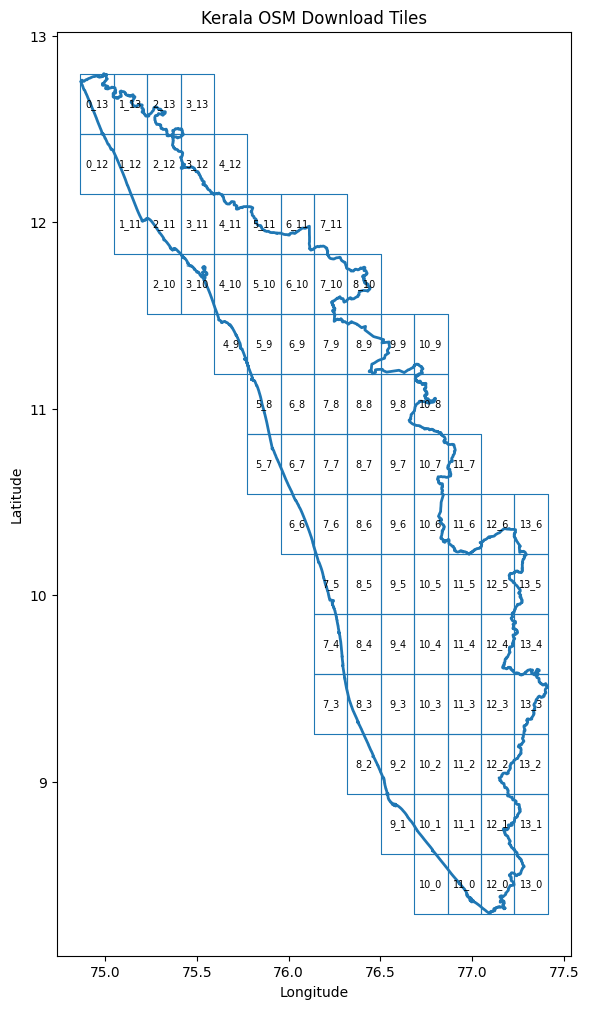

In [22]:
# Visualize OSM download tiles

import matplotlib.pyplot as plt
import geopandas as gpd

# Convert grid tiles into GeoDataFrame
tiles_gdf = gpd.GeoDataFrame(
    {
        "tile_id": [tile_id for tile_id, geom in base_tiles],
        "geometry": [geom for tile_id, geom in base_tiles]
    },
    crs="EPSG:4326"
)

fig, ax = plt.subplots(figsize=(10, 12))

# Kerala boundary
kerala_boundary.boundary.plot(
    ax=ax,
    linewidth=2
)

# Grid tiles
tiles_gdf.boundary.plot(
    ax=ax,
    linewidth=0.8
)

# Add tile labels
for _, row in tiles_gdf.iterrows():

    point = row.geometry.representative_point()

    ax.text(
        point.x,
        point.y,
        row["tile_id"],
        fontsize=7,
        ha="center",
        va="center"
    )

ax.set_title("Kerala OSM Download Tiles")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()

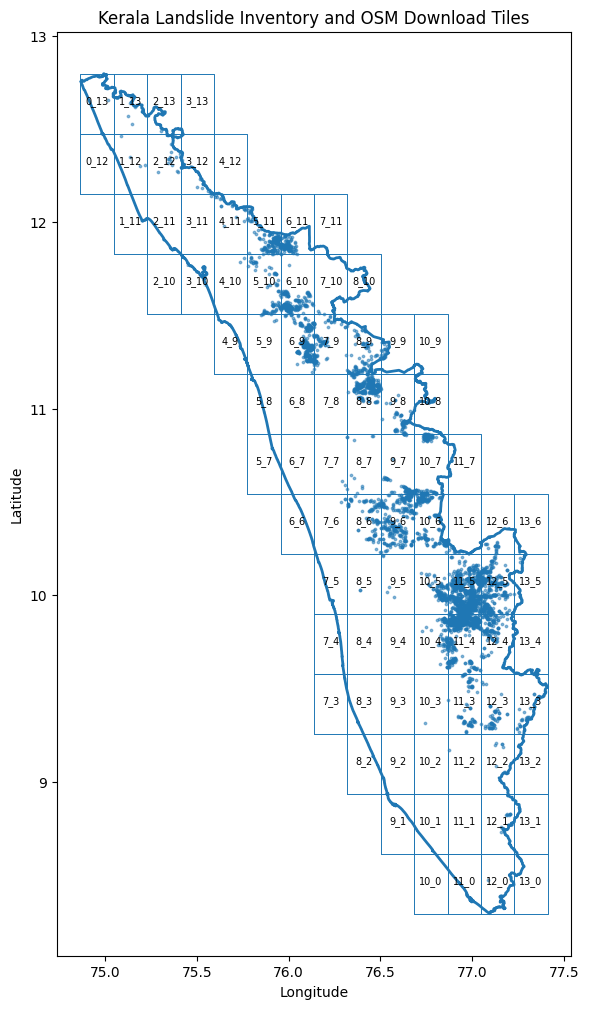

In [23]:
# Visualize tiles with Kerala landslide points

fig, ax = plt.subplots(figsize=(10, 12))

# Kerala boundary
kerala_boundary.boundary.plot(
    ax=ax,
    linewidth=2
)

# Grid
tiles_gdf.boundary.plot(
    ax=ax,
    linewidth=0.7
)

# Landslide locations
kerala_wgs84.plot(
    ax=ax,
    markersize=3,
    alpha=0.5
)

# Tile IDs
for _, row in tiles_gdf.iterrows():

    point = row.geometry.representative_point()

    ax.text(
        point.x,
        point.y,
        row["tile_id"],
        fontsize=7,
        ha="center"
    )

ax.set_title(
    "Kerala Landslide Inventory and OSM Download Tiles"
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()

In [25]:
# Count landslide points per tile

tile_counts = []

for tile_id, tile_geom in base_tiles:

    count = kerala_wgs84.geometry.within(
        tile_geom
    ).sum()

    tile_counts.append(
        {
            "tile_id": tile_id,
            "landslide_count": count
        }
    )

tile_counts

[{'tile_id': '0_12', 'landslide_count': 0},
 {'tile_id': '0_13', 'landslide_count': 1},
 {'tile_id': '1_11', 'landslide_count': 0},
 {'tile_id': '1_12', 'landslide_count': 4},
 {'tile_id': '1_13', 'landslide_count': 4},
 {'tile_id': '2_10', 'landslide_count': 0},
 {'tile_id': '2_11', 'landslide_count': 0},
 {'tile_id': '2_12', 'landslide_count': 14},
 {'tile_id': '2_13', 'landslide_count': 1},
 {'tile_id': '3_10', 'landslide_count': 0},
 {'tile_id': '3_11', 'landslide_count': 1},
 {'tile_id': '3_12', 'landslide_count': 9},
 {'tile_id': '3_13', 'landslide_count': 0},
 {'tile_id': '4_9', 'landslide_count': 0},
 {'tile_id': '4_10', 'landslide_count': 2},
 {'tile_id': '4_11', 'landslide_count': 20},
 {'tile_id': '4_12', 'landslide_count': 0},
 {'tile_id': '5_7', 'landslide_count': 0},
 {'tile_id': '5_8', 'landslide_count': 0},
 {'tile_id': '5_9', 'landslide_count': 6},
 {'tile_id': '5_10', 'landslide_count': 78},
 {'tile_id': '5_11', 'landslide_count': 156},
 {'tile_id': '6_6', 'landslide_

In [26]:
import pandas as pd

tile_counts_df = pd.DataFrame(tile_counts)

tile_counts_df.sort_values(
    "landslide_count",
    ascending=False
)

,tile_id,landslide_count
70,11_5,873
69,11_4,704
78,12_5,345
43,8_8,336
51,9_6,278
...,...,...
47,9_2,0
48,9_3,0
49,9_4,0
55,10_0,0


In [16]:
#Rivers
river_tags = {
    "waterway": [
        "river",
        "stream"
    ]
}

#Roads
road_tags = {
    "highway": True
}

In [18]:
# Download rivers

print("\n==============================")
print("DOWNLOADING RIVERS")
print("==============================")

river_failures = []
for tile_id, geom in base_tiles:
    river_failures += fetch_tile_recursive(tile_id, geom, river_tags, "rivers", OSM_DIR)
    time.sleep(8)


DOWNLOADING RIVERS
Fetching rivers tile 3_10 (depth 0)...
    ConnectTimeout, retrying in 10s...
    ConnectTimeout, retrying in 20s...
    ReadTimeout, retrying in 10s...
    ReadTimeout, retrying in 20s...
    ConnectionError, retrying in 10s...
    ConnectionError, retrying in 20s...
  Fetching rivers tile 3_10_1 (depth 1)...
    ConnectionError, retrying in 10s...
    ConnectionError, retrying in 20s...


KeyboardInterrupt: 

### OSM-02

In [43]:
# Kerala districts available in the landslide inventory

districts = sorted(
    kerala_wgs84["District"]
    .dropna()
    .astype(str)
    .str.strip()
    .unique()
)

print("Number of districts:", len(districts))

for district in districts:
    print(district)

Number of districts: 13
Ernakulam
Idukki
Kannur
Kasaragod
Kollam
Kottayam
Kozhikode
Malappuram
Palakkad
Pathanamthitta
Thiruvananthapuram
Thrissur
Wayanad


In [44]:
#Get district boundaries from OSM and cache them
import osmnx as ox
import geopandas as gpd
import pandas as pd
import time

district_boundary_file = (
    PROCESSED_DIR / "kerala_district_boundaries.gpkg"
)

if district_boundary_file.exists():

    print("Loading saved Kerala district boundaries...")

    aoi_wgs84 = gpd.read_file(
        district_boundary_file
    )

else:

    print("Downloading Kerala district boundaries...")

    district_boundaries = []

    for district_name in districts:

        print("Finding:", district_name)

        try:

            boundary = ox.geocode_to_gdf(
                f"{district_name}, Kerala, India"
            )

            boundary["District"] = district_name

            district_boundaries.append(
                boundary[["District", "geometry"]]
            )

            time.sleep(1)

        except Exception as e:

            print(
                f"FAILED {district_name}: {e}"
            )

    aoi_wgs84 = pd.concat(
        district_boundaries,
        ignore_index=True
    )

    aoi_wgs84 = gpd.GeoDataFrame(
        aoi_wgs84,
        geometry="geometry",
        crs="EPSG:4326"
    )

    aoi_wgs84.to_file(
        district_boundary_file,
        driver="GPKG"
    )

    print(
        "Saved:",
        district_boundary_file
    )


print(aoi_wgs84[["District"]])


Finding: Ernakulam
Finding: Idukki
Finding: Kannur
Finding: Kasaragod
Finding: Kollam
Finding: Kottayam
Finding: Kozhikode
Finding: Malappuram
Finding: Palakkad
Finding: Pathanamthitta
Finding: Thiruvananthapuram
Finding: Thrissur
Finding: Wayanad
Saved: D:\PROJECTS\Landslide_prediction\data\processed\kerala_district_boundaries.gpkg
              District
0            Ernakulam
1               Idukki
2               Kannur
3            Kasaragod
4               Kollam
5             Kottayam
6            Kozhikode
7           Malappuram
8             Palakkad
9       Pathanamthitta
10  Thiruvananthapuram
11            Thrissur
12             Wayanad


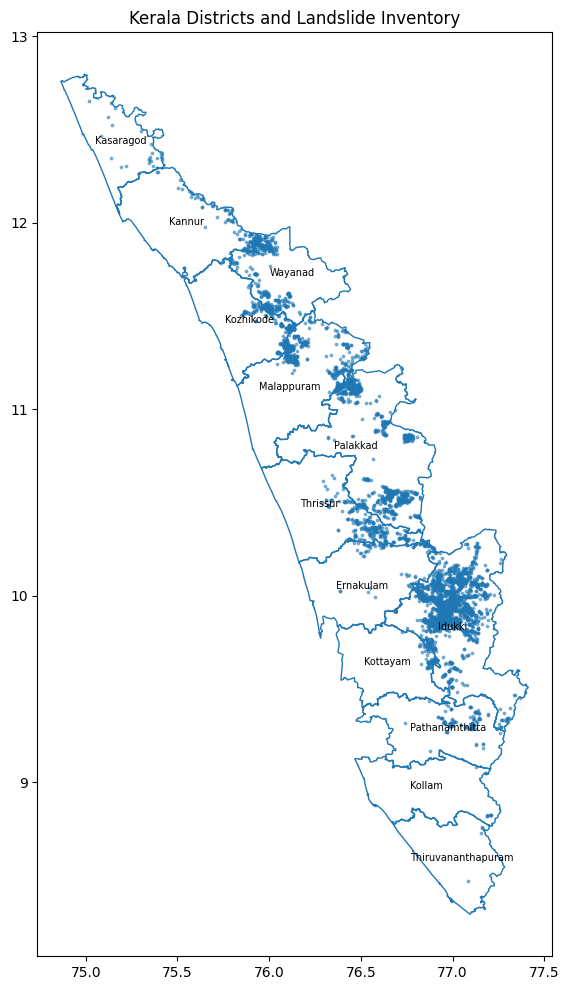

In [45]:
#Visualize Kerala districts and landslide inventory
import matplotlib.pyplot as plt

fig, ax = plt.subplots(
    figsize=(10, 12)
)

# District boundaries
aoi_wgs84.boundary.plot(
    ax=ax,
    linewidth=1
)

# Landslide locations
kerala_wgs84.plot(
    ax=ax,
    markersize=3,
    alpha=0.5
)

# District names
for _, row in aoi_wgs84.iterrows():

    point = row.geometry.representative_point()

    ax.text(
        point.x,
        point.y,
        row["District"],
        fontsize=7,
        ha="center"
    )

ax.set_title(
    "Kerala Districts and Landslide Inventory"
)

plt.show()

In [46]:
SM_DIR = (
    PROCESSED_DIR /
    "kerala_osm_checkpoints"
)

OSM_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("OSM folder:", OSM_DIR)

OSM folder: D:\PROJECTS\Landslide_prediction\data\raw\Kerala_dataset\osm_tiles


In [47]:
import time


def fetch_osm_with_retry(
    polygon,
    tags,
    retries=3,
    base_wait=5
):

    for attempt in range(retries):

        try:

            return ox.features_from_polygon(
                polygon,
                tags=tags
            )

        except Exception as e:

            wait = base_wait * (attempt + 1)

            print(
                f"    attempt {attempt + 1}/{retries} failed: "
                f"{type(e).__name__}"
            )

            print(
                f"    retrying in {wait} seconds..."
            )

            time.sleep(wait)

    raise RuntimeError(
        f"Failed after {retries} attempts"
    )

In [48]:
# Download Kerala rivers and roads district-by-district

for _, row in aoi_wgs84.iterrows():

    district_name = row["District"]
    geom = row.geometry

    # Clean filename
    safe_name = (
        district_name
        .replace(" ", "_")
        .replace("/", "_")
    )


    rivers_path = (
        OSM_DIR /
        f"rivers_{safe_name}.gpkg"
    )

    roads_path = (
        OSM_DIR /
        f"roads_{safe_name}.gpkg"
    )


    print(
        f"\n=============================="
        f"\n{district_name}"
        f"\n=============================="
    )


    # ============================================
    # RIVERS
    # ============================================

    if rivers_path.exists():

        print("Rivers already downloaded.")

    else:

        try:

            print("Fetching rivers...")

            rivers = fetch_osm_with_retry(
                geom,
                {
                    "waterway": [
                        "river",
                        "stream"
                    ]
                }
            )


            # Keep line features only
            rivers = rivers[
                rivers.geometry.geom_type.isin(
                    [
                        "LineString",
                        "MultiLineString"
                    ]
                )
            ].copy()


            # IMPORTANT:
            # We only need geometry for distance calculation
            rivers = rivers[
                ["geometry"]
            ].copy()

            rivers["District"] = district_name


            rivers.to_file(
                rivers_path,
                driver="GPKG"
            )


            print(
                f"✅ Rivers saved: "
                f"{len(rivers)}"
            )


        except Exception as e:

            print(
                f"❌ Rivers FAILED for "
                f"{district_name}: {e}"
            )


    # ============================================
    # ROADS
    # ============================================

    if roads_path.exists():

        print("Roads already downloaded.")

    else:

        try:

            print("Fetching roads...")

            roads = fetch_osm_with_retry(
                geom,
                {
                    "highway": True
                }
            )


            # Keep line geometries only
            roads = roads[
                roads.geometry.geom_type.isin(
                    [
                        "LineString",
                        "MultiLineString"
                    ]
                )
            ].copy()


            # IMPORTANT:
            # Removes problematic OSM columns
            # such as FIXME/fixme
            roads = roads[
                ["geometry"]
            ].copy()

            roads["District"] = district_name


            roads.to_file(
                roads_path,
                driver="GPKG"
            )


            print(
                f"Roads saved: "
                f"{len(roads)}"
            )


        except Exception as e:

            print(
                f"Roads FAILED for "
                f"{district_name}: {e}"
            )


    time.sleep(2)


Ernakulam
Fetching rivers...


KeyboardInterrupt: 

In [49]:
import time
import geopandas as gpd
import osmnx as ox


def fetch_osm_district(geom, tags, retries=2):
    """
    Download OSM data using the district bounding box,
    then clip the result back to the actual district boundary.
    """

    # District bounding box
    minx, miny, maxx, maxy = geom.bounds

    # OSMnx expects:
    # (left, bottom, right, top)
    bbox = (minx, miny, maxx, maxy)

    for attempt in range(retries):

        try:
            print(
                f"    request {attempt + 1}/{retries}"
            )

            features = ox.features_from_bbox(
                bbox,
                tags=tags
            )

            # Keep useful line geometries only
            features = features[
                features.geometry.geom_type.isin(
                    ["LineString", "MultiLineString"]
                )
            ].copy()

            if len(features) == 0:
                return features

            # Create district polygon GeoDataFrame
            district_gdf = gpd.GeoDataFrame(
                {"geometry": [geom]},
                crs="EPSG:4326"
            )

            # Clip downloaded bbox data
            # back to exact district boundary
            features = gpd.clip(
                features,
                district_gdf
            )

            return features

        except Exception as e:

            print(
                f"    failed: {type(e).__name__}: {e}"
            )

            time.sleep(5)

    raise RuntimeError(
        "OSM download failed after retries."
    )

In [50]:
print("Fetching rivers...")

rivers = fetch_osm_district(
    geom,
    {
        "waterway": [
            "river",
            "stream"
        ]
    }
)

rivers = rivers[["geometry"]].copy()
rivers["District"] = district_name

rivers.to_file(
    rivers_path,
    driver="GPKG"
)

print(
    f"Rivers saved: {len(rivers)}"
)

Fetching rivers...
    request 1/2


KeyboardInterrupt: 

In [ ]:
# 12 — Merge completed OSM tile files
def merge_osm_tiles(prefix):
    files = sorted(OSM_DIR.glob(f'{prefix}_*.gpkg'))
    parts = []
    for p in files:
        g = gpd.read_file(p)
        if len(g):
            parts.append(g[['geometry']])
    if not parts:
        raise RuntimeError(f'No {prefix} line features were downloaded.')
    merged = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), geometry='geometry', crs=parts[0].crs)
    merged = merged.to_crs(TARGET_CRS)
    merged = merged[merged.geometry.notna() & ~merged.geometry.is_empty].copy()
    # Remove exact duplicate geometries.
    merged['_wkb'] = merged.geometry.to_wkb()
    merged = merged.drop_duplicates('_wkb').drop(columns='_wkb').reset_index(drop=True)
    return merged

rivers_utm = merge_osm_tiles('rivers')
roads_utm = merge_osm_tiles('roads')

print('Merged rivers:', len(rivers_utm))
print('Merged roads :', len(roads_utm))


### OSM-03

In [31]:
! pip install -U scipy --break-system-packages

   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.3/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.3/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.3/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.3/36.6 MB ? eta -:--:--
   ---------------------------------------- 0.3/36.6 MB ? eta -:--:--
   -----------------

  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.3 requires numpy<2.0,>=1.18.5, but you have numpy 2.4.6 which is incompatible.
gensim 4.3.3 requires scipy<1.14.0,>=1.7.0, but you have scipy 1.17.1 which is incompatible.

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: C:\Users\PCC\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [33]:
! pip uninstall scipy -y

Found existing installation: scipy 1.17.1
Uninstalling scipy-1.17.1:
  Successfully uninstalled scipy-1.17.1


In [35]:
! pip uninstall scipy -y

In [36]:
! pip show scipy

In [37]:
! pip install scipy --break-system-packages

  Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl.metadata (60 kB)
Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl (36.6 MB)


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.3 requires numpy<2.0,>=1.18.5, but you have numpy 2.4.6 which is incompatible.
gensim 4.3.3 requires scipy<1.14.0,>=1.7.0, but you have scipy 1.17.1 which is incompatible.

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: C:\Users\PCC\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [11]:
import time
import numpy as np
import pandas as pd
import geopandas as gpd
import osmnx as ox
import rasterio
from rasterio.features import rasterize
from scipy.ndimage import distance_transform_edt

OSM_CHECKPOINT_DIR = PROCESSED_DIR / "osm_checkpoints"
OSM_CHECKPOINT_DIR.mkdir(exist_ok=True)

# District list from your landslide inventory
districts = sorted(kerala_wgs84["District"].dropna().astype(str).str.strip().unique())
print(f"{len(districts)} districts:", districts)

# District boundaries (cached — reuse if you already built this)
district_boundary_file = PROCESSED_DIR / "kerala_district_boundaries.gpkg"
if district_boundary_file.exists():
    aoi_wgs84 = gpd.read_file(district_boundary_file)
    print("Loaded cached district boundaries.")
else:
    boundaries = []
    for name in districts:
        try:
            b = ox.geocode_to_gdf(f"{name}, Kerala, India")
            b["District"] = name
            boundaries.append(b[["District", "geometry"]])
            time.sleep(1)
        except Exception as e:
            print(f"FAILED {name}: {e}")
    aoi_wgs84 = gpd.GeoDataFrame(pd.concat(boundaries, ignore_index=True), crs="EPSG:4326")
    aoi_wgs84.to_file(district_boundary_file, driver="GPKG")
    print("Saved district boundaries.")

13 districts: ['Ernakulam', 'Idukki', 'Kannur', 'Kasaragod', 'Kollam', 'Kottayam', 'Kozhikode', 'Malappuram', 'Palakkad', 'Pathanamthitta', 'Thiruvananthapuram', 'Thrissur', 'Wayanad']
Loaded cached district boundaries.


In [ ]:
#Retry helper
def fetch_osm_with_retry(polygon, tags, retries=3, base_wait=5):
    """Fetch OSM features for one polygon, retrying on connection/timeout errors."""
    for attempt in range(retries):
        try:
            return ox.features_from_polygon(polygon, tags=tags)
        except Exception as e:
            wait = base_wait * (attempt + 1)
            print(f"    attempt {attempt+1}/{retries} failed ({type(e).__name__}); retrying in {wait}s...")
            time.sleep(wait)
    raise RuntimeError(f"Failed after {retries} attempts")

def clean_roads(roads_gdf, district_name):
    """Keep only geometry + highway — avoids the GPKG FIXME/fixme field collision entirely."""
    keep_cols = [c for c in ["geometry", "highway"] if c in roads_gdf.columns]
    cleaned = roads_gdf[keep_cols].copy()
    cleaned["district"] = district_name
    return cleaned

def clean_rivers(rivers_gdf, district_name):
    cleaned = rivers_gdf[["geometry"]].copy()
    cleaned["district"] = district_name
    return cleaned

In [13]:
#Main per-district fetch loop (checkpointed)
river_tags = {"waterway": ["river", "stream"]}
road_tags = {"highway": True}

for _, row in aoi_wgs84.iterrows():
    district_name = row["District"]
    geom = row.geometry

    rivers_path = OSM_CHECKPOINT_DIR / f"rivers_{district_name}.parquet"
    roads_path = OSM_CHECKPOINT_DIR / f"roads_{district_name}.parquet"

    print(f"\n=== {district_name} ===")

    if rivers_path.exists():
        print("  rivers already fetched")
    else:
        try:
            rivers = fetch_osm_with_retry(geom, river_tags)
            rivers = rivers[rivers.geometry.geom_type.isin(["LineString", "MultiLineString"])]
            rivers = clean_rivers(rivers, district_name)
            rivers.to_parquet(rivers_path)
            print(f"  rivers: {len(rivers)} saved")
        except Exception as e:
            print(f"  rivers FAILED: {e}")

    if roads_path.exists():
        print("  roads already fetched")
    else:
        try:
            roads = fetch_osm_with_retry(geom, road_tags)
            roads = roads[roads.geometry.geom_type.isin(["LineString", "MultiLineString"])]
            roads = clean_roads(roads, district_name)
            roads.to_parquet(roads_path)
            print(f"  roads: {len(roads)} saved")
        except Exception as e:
            print(f"  roads FAILED: {e}")

    time.sleep(2)


=== Ernakulam ===
    attempt 1/3 failed (ConnectTimeout); retrying in 5s...
    attempt 2/3 failed (ConnectTimeout); retrying in 10s...
    attempt 3/3 failed (ConnectTimeout); retrying in 15s...
  rivers FAILED: Failed after 3 attempts


KeyboardInterrupt: 

## 7. Generate balanced pseudo-absence points

The master inventory stays at 4,728 landslides. For the training table, generate **4,728 pseudo-absence points** (`label=0`) inside Kerala, on valid DEM cells, and at least 1 km from every known landslide. The random seed is fixed for reproducibility.


In [ ]:
# 13 — Prepare landslide points for modelling
landslides_utm = kerala_wgs84.to_crs(TARGET_CRS).copy()
landslides_utm['lslpts'] = 'TRUE'
landslides_utm['label'] = 1
landslides_utm['source'] = 'Kerala_Landslide_Inventory'
landslides_utm['X'] = landslides_utm.geometry.x
landslides_utm['Y'] = landslides_utm.geometry.y

state_utm = kerala_boundary.to_crs(TARGET_CRS)
state_geom_utm = state_utm.geometry.union_all()
exclusion_geom = landslides_utm.geometry.buffer(EXCLUSION_BUFFER_M).union_all()
allowed_geom = state_geom_utm.difference(exclusion_geom)

assert not allowed_geom.is_empty
print('Landslide samples:', len(landslides_utm))
print('Pseudo-absence target:', len(landslides_utm))


In [ ]:
# 14 — Reproducible pseudo-absence sampling
def generate_pseudo_absences(n_required, allowed_polygon, dem_path, seed=42, batch_size=20000):
    rng = np.random.default_rng(seed)
    allowed_prepared = prep(allowed_polygon)
    minx, miny, maxx, maxy = allowed_polygon.bounds
    accepted = []
    seen = set()

    with rasterio.open(dem_path) as dem:
        nodata = dem.nodata
        while len(accepted) < n_required:
            xs = rng.uniform(minx, maxx, batch_size)
            ys = rng.uniform(miny, maxy, batch_size)
            candidates = []
            for x, y in zip(xs, ys):
                p = Point(float(x), float(y))
                if allowed_prepared.contains(p):
                    key = (round(x, 3), round(y, 3))
                    if key not in seen:
                        candidates.append(p)
                        seen.add(key)

            if not candidates:
                continue

            vals = np.array([v[0] for v in dem.sample([(p.x, p.y) for p in candidates])], dtype='float64')
            valid = np.isfinite(vals)
            if nodata is not None:
                valid &= vals != nodata

            for p, ok in zip(candidates, valid):
                if ok:
                    accepted.append(p)
                    if len(accepted) == n_required:
                        break

            print(f'Accepted {len(accepted):,}/{n_required:,}', end='\r')

    print()
    return gpd.GeoDataFrame({'geometry': accepted}, crs=TARGET_CRS)

NONLANDSLIDE_GPKG = PROCESSED_DIR / 'kerala_pseudo_absence_points.gpkg'

if NONLANDSLIDE_GPKG.exists():
    non_landslides_utm = gpd.read_file(NONLANDSLIDE_GPKG)
    if len(non_landslides_utm) != len(landslides_utm):
        raise ValueError('Cached pseudo-absence count does not match landslide count. Delete it and regenerate.')
    print('Loaded cached pseudo-absence points.')
else:
    non_landslides_utm = generate_pseudo_absences(
        len(landslides_utm), allowed_geom, DEM_UTM, seed=RANDOM_STATE
    )
    non_landslides_utm.to_file(NONLANDSLIDE_GPKG, layer='pseudo_absence', driver='GPKG')
    print('Saved pseudo-absence points:', NONLANDSLIDE_GPKG)

non_landslides_utm['lslpts'] = 'FALSE'
non_landslides_utm['label'] = 0
non_landslides_utm['source'] = 'Kerala_Pseudo_Absence'
non_landslides_utm['X'] = non_landslides_utm.geometry.x
non_landslides_utm['Y'] = non_landslides_utm.geometry.y

print(non_landslides_utm['label'].value_counts())

def fetch_tiled_layer(layer_name, tags):

    failures = []

    for tile_id, tile_geom in grid_tiles:

        out_file = OSM_DIR / f"{layer_name}_{tile_id}.gpkg"
        done_file = OSM_DIR / f"{layer_name}_{tile_id}.done"


        # --------------------------------------------------
        # Skip tiles that were already successfully completed
        # --------------------------------------------------

        if done_file.exists():

            print(
                f"Skipping {layer_name} tile {tile_id} "
                "(already completed)"
            )

            continue


        print(f"\nFetching {layer_name} tile {tile_id}...")


        # --------------------------------------------------
        # Download
        # --------------------------------------------------

        gdf, error = fetch_osm_with_fallback(
            tile_geom,
            tags
        )


        # --------------------------------------------------
        # If all servers failed
        # --------------------------------------------------

        if gdf is None:

            print(
                f"❌ Failed {layer_name} tile {tile_id}"
            )

            failures.append(
                (tile_id, str(error))
            )

            continue


        # --------------------------------------------------
        # Keep only line geometries
        # --------------------------------------------------

        if len(gdf) > 0:

            gdf = gdf[
                gdf.geometry.geom_type.isin(
                    [
                        "LineString",
                        "MultiLineString"
                    ]
                )
            ].copy()


        # --------------------------------------------------
        # Save tile
        # --------------------------------------------------

        if len(gdf) > 0:

            gdf[["geometry"]].to_file(
                out_file,
                layer=layer_name,
                driver="GPKG"
            )


        # --------------------------------------------------
        # Mark successful query as completed
        # --------------------------------------------------

        done_file.write_text(
            "query completed",
            encoding="utf-8"
        )


        print(
            f"✅ Completed {layer_name} "
            f"tile {tile_id}: "
            f"{len(gdf)} line features"
        )


        # Be polite to public Overpass servers
        time.sleep(3)


    return failures

# ---------------------------------------------------------
# River tags
# ---------------------------------------------------------

river_tags = {
    "waterway": [
        "river",
        "stream"
    ]
}


# ---------------------------------------------------------
# Road tags
# ---------------------------------------------------------

road_tags = {
    "highway": True
}


# ---------------------------------------------------------
# Download rivers first
# ---------------------------------------------------------

print("\n==============================")
print("DOWNLOADING RIVERS")
print("==============================")

river_failures = fetch_tiled_layer(
    "rivers",
    river_tags
)


# ---------------------------------------------------------
# Download roads
# ---------------------------------------------------------

print("\n==============================")
print("DOWNLOADING ROADS")
print("==============================")

road_failures = fetch_tiled_layer(
    "roads",
    road_tags
)


# ---------------------------------------------------------
# Report
# ---------------------------------------------------------

print("\n==============================")
print("DOWNLOAD SUMMARY")
print("==============================")

print(
    "River failed tiles:",
    len(river_failures)
)

print(
    "Road failed tiles:",
    len(road_failures)
)


if river_failures:

    print("\nRiver failures:")

    for tile_id, error in river_failures:
        print(tile_id, error)


if road_failures:

    print("\nRoad failures:")

    for tile_id, error in road_failures:
        print(tile_id, error)


if not river_failures and not road_failures:

    print(
        "\n✅ All OSM river and road tiles completed."
    )

else:

    print(
        "\n⚠ Some tiles failed."
        "\nSimply rerun THIS CELL."
        "\nCompleted tiles will automatically be skipped."
    )

## 8. Combine the two classes and calculate road/river distances

The base columns now mirror the Indonesia table: `lslpts`, `X`, `Y`, `geometry`, `label`, `source`. Distances are calculated in metres because all layers are in EPSG:32643.


In [ ]:
# 15 — Build balanced modelling points
base_cols = ['lslpts', 'X', 'Y', 'geometry', 'label', 'source']
combined = pd.concat(
    [landslides_utm[base_cols], non_landslides_utm[base_cols]],
    ignore_index=True
)
combined = gpd.GeoDataFrame(combined, geometry='geometry', crs=TARGET_CRS)

print(combined['label'].value_counts())
print('Total:', len(combined))
assert combined['label'].value_counts().nunique() == 1, 'Classes are not balanced.'


In [ ]:
# 16 — Nearest distance helper and OSM distance factors
def nearest_distance(left_points, right_features, out_name):
    joined = gpd.sjoin_nearest(
        left_points[['geometry']],
        right_features[['geometry']],
        how='left',
        distance_col=out_name
    )
    # Equidistant ties can create repeated left indices; keep the minimum distance.
    dist = joined.groupby(level=0)[out_name].min()
    return dist.reindex(left_points.index).to_numpy()

combined['distriv'] = nearest_distance(combined, rivers_utm, 'distriv')
combined['distroad'] = nearest_distance(combined, roads_utm, 'distroad')

print(combined[['distriv', 'distroad']].describe())
assert combined[['distriv', 'distroad']].notna().all().all(), 'Missing road/river distances found.'


## 9. Sample raster conditioning factors at every point


In [ ]:
# 17 — Raster sampling helper
def sample_raster_at_points(raster_path, points_gdf, band=1):
    raster_path = Path(raster_path)
    with rasterio.open(raster_path) as src:
        pts = points_gdf.to_crs(src.crs) if points_gdf.crs != src.crs else points_gdf
        coords = [(geom.x, geom.y) for geom in pts.geometry]
        values = np.array([v[band - 1] for v in src.sample(coords)], dtype='float64')
        if src.nodata is not None:
            values[values == src.nodata] = np.nan
        values[~np.isfinite(values)] = np.nan
        return values

terrain_rasters = {
    'elev': DEM_UTM,
    'aspect': ASPECT,
    'planc': PLANC,
    'profc': PROFC,
    'slope': SLOPE,
    'spi': SPI,
    'twi': TWI,
}

for name, path in terrain_rasters.items():
    combined[name] = sample_raster_at_points(path, combined)
    print(f'{name:8s}: {combined[name].notna().sum():,}/{len(combined):,} valid')


## 10. Geology and land-use

The uploaded Kerala ZIP does not contain Kerala-wide geology and land-use layers that can be sampled at **both** landslide and pseudo-absence points. Do not fill these columns from the landslide inventory's `LU_2010`/`LU_2018` fields because those attributes exist only for known landslide records.

This section accepts either:
- a categorical/numeric raster (`.tif`), or
- a polygon vector layer (`.shp`, `.gpkg`) plus the category field name.

If these inputs are left as `None`, the notebook still saves a valid **core** susceptibility dataset but does not claim it is the exact 11-factor Indonesia-equivalent dataset.


In [ ]:
# 18 — Optional categorical factor loader
def add_factor(points_gdf, source_path, out_col, category_field=None):
    if source_path is None:
        points_gdf[out_col] = np.nan
        return None

    source_path = Path(source_path)
    if not source_path.exists():
        raise FileNotFoundError(source_path)

    if source_path.suffix.lower() in ['.tif', '.tiff']:
        points_gdf[out_col] = sample_raster_at_points(source_path, points_gdf)
        return None

    vector = gpd.read_file(source_path).to_crs(points_gdf.crs)
    if category_field is None or category_field not in vector.columns:
        raise ValueError(f'{out_col}: provide a valid category field for vector data.')

    joined = gpd.sjoin(
        points_gdf[['geometry']],
        vector[[category_field, 'geometry']],
        how='left',
        predicate='within'
    )
    values = joined.groupby(level=0)[category_field].first().reindex(points_gdf.index)

    # Stable integer coding for categorical text. Save the mapping for reproducibility.
    if not pd.api.types.is_numeric_dtype(values):
        categories = sorted(v for v in values.dropna().astype(str).unique())
        mapping = {cat: i + 1 for i, cat in enumerate(categories)}
        points_gdf[out_col] = values.astype('string').map(mapping).astype('float64')
        map_df = pd.DataFrame({category_field: list(mapping.keys()), f'{out_col}_code': list(mapping.values())})
        map_df.to_csv(PROCESSED_DIR / f'{out_col}_category_mapping.csv', index=False)
        return mapping

    points_gdf[out_col] = pd.to_numeric(values, errors='coerce')
    return None

geology_mapping = add_factor(combined, GEOLOGY_PATH, 'geologi', GEOLOGY_FIELD)
landuse_mapping = add_factor(combined, LANDUSE_PATH, 'landuse', LANDUSE_FIELD)

print('Geology valid:', combined['geologi'].notna().sum(), '/', len(combined))
print('Land-use valid:', combined['landuse'].notna().sum(), '/', len(combined))


## 11. Quality checks and save outputs

The exact Indonesia-style order is:

`lslpts, X, Y, geometry, label, source, aspect, distriv, distroad, elev, geologi, landuse, planc, profc, slope, spi, twi`


In [ ]:
# 19 — Quality-control report
indonesia_style_columns = [
    'lslpts', 'X', 'Y', 'geometry', 'label', 'source',
    'aspect', 'distriv', 'distroad', 'elev', 'geologi', 'landuse',
    'planc', 'profc', 'slope', 'spi', 'twi'
]
core_factor_columns = [
    'aspect', 'distriv', 'distroad', 'elev',
    'planc', 'profc', 'slope', 'spi', 'twi'
]

print('Rows:', len(combined))
print('Class balance:')
print(combined['label'].value_counts())
print('\nMissing values (%):')
print((combined[indonesia_style_columns].isna().mean() * 100).round(2))
print('\nDuplicate modelling geometries:', combined.geometry.duplicated().sum())

# Core factors should be complete. If not, inspect before training instead of silently dropping rows.
core_missing = combined[core_factor_columns].isna().sum()
if core_missing.any():
    print('\nWARNING — missing core factors:')
    print(core_missing[core_missing > 0])
else:
    print('\nAll core factors are complete.')


In [ ]:
# 20 — Save core CSV and exact Indonesia-style dataset when possible
CORE_COLUMNS = [
    'lslpts', 'X', 'Y', 'geometry', 'label', 'source',
    'aspect', 'distriv', 'distroad', 'elev',
    'planc', 'profc', 'slope', 'spi', 'twi'
]

def save_geocsv(gdf, path, columns):
    out = gdf[columns].copy()
    out['geometry'] = out.geometry.to_wkt()
    out.to_csv(path, index=False, encoding='utf-8-sig')
    return path

CORE_CSV = PROCESSED_DIR / 'training_table_kerala_core.csv'
save_geocsv(combined, CORE_CSV, CORE_COLUMNS)
print('Saved core CSV:', CORE_CSV)

exact_ready = combined[['geologi', 'landuse']].notna().all().all()
if exact_ready:
    final = combined[indonesia_style_columns].copy()
    FINAL_CSV = PROCESSED_DIR / 'training_table_kerala.csv'
    FINAL_PARQUET = PROCESSED_DIR / 'training_table_kerala.parquet'

    save_geocsv(final, FINAL_CSV, indonesia_style_columns)
    final.to_parquet(FINAL_PARQUET, index=False)

    print('\nEXACT Indonesia-style Kerala dataset created.')
    print('CSV    :', FINAL_CSV)
    print('Parquet:', FINAL_PARQUET)
    print('Shape  :', final.shape)
else:
    print('\nCore dataset created, but exact 17-column dataset is NOT finalized yet.')
    print('Add valid Kerala-wide GEOLOGY_PATH and LANDUSE_PATH, then rerun Cells 18–20.')


In [ ]:
# 21 — Save a reproducibility manifest
manifest = {
    'created_utc': datetime.now(timezone.utc).isoformat(),
    'source_zip': str(ZIP_PATH),
    'source_landslide_count': int(len(kerala_raw)),
    'pseudo_absence_count': int((combined['label'] == 0).sum()),
    'target_crs': TARGET_CRS,
    'target_resolution_m': TARGET_RESOLUTION_M,
    'random_state': RANDOM_STATE,
    'exclusion_buffer_m': EXCLUSION_BUFFER_M,
    'osm_grid_n': N_GRID,
    'geology_path': None if GEOLOGY_PATH is None else str(GEOLOGY_PATH),
    'landuse_path': None if LANDUSE_PATH is None else str(LANDUSE_PATH),
    'exact_indonesia_style_ready': bool(exact_ready),
}

MANIFEST_PATH = PROCESSED_DIR / 'kerala_dataset_manifest.json'
MANIFEST_PATH.write_text(json.dumps(manifest, indent=2), encoding='utf-8')
print(json.dumps(manifest, indent=2))


## Expected research outputs

After the notebook runs:

- `kerala_landslide_master.csv` — all 4,728 original landslide inventory rows; no pseudo-absence rows.
- `kerala_landslide_master.gpkg` — same master inventory with native GIS geometry.
- `kerala_pseudo_absence_points.gpkg` — reproducible `label=0` points generated with seed 42.
- `training_table_kerala_core.csv` — balanced susceptibility table using the factors that can be built from the current source plus OSM.
- `training_table_kerala.csv` / `.parquet` — created only when valid Kerala-wide geology and land-use layers are supplied, with the same 17-column naming/order as the Indonesia table.
- `kerala_dataset_manifest.json` — records the main preprocessing choices for reproducibility.

### Important
Do not use `LU_2010` or `LU_2018` from the original landslide inventory as the final `landuse` predictor unless you have the corresponding **full spatial land-use layer** for sampling the pseudo-absence points as well.
